<a href="https://colab.research.google.com/github/Virna-Valentina/Entregables-Virna-Rodriguez/blob/main/Actividad__3_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


**Actividad 3: Taller EDA**

*He seleccionado una base de datos que consolida los pagos, retenciones y ajustes realizados a una agencia, (Pago de comisiones por seguros de salud)*

•  Exploración de datos nulos, datos duplicados, cantidad de filas y columnas.


In [7]:
#Importa librerias
import pandas as pd
import numpy as np
from google.colab import drive
drive.mount('/content/drive')

df = pd.read_excel('/content/drive/MyDrive/Classroom/DB-Ejemplo-Talle EDA.xlsx')
df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,id,name,payment_status,payment_type,policy_type,pay_on_date,commission_month,receveid_date,pre_approved,processing_status,...,triggered_from_contact,first_payment,created_date,last_modified_date,internal_company_id,carrier_state_line_of_business_id,book_of_business_id,contact_payee_id,reconciliations_id,commission_in_advance_id
0,a0AUh000000lx77MAA,PM-7166413,Paid,Override,New Sale,2026-06-04,2024-02-01,2024-03-20,Yes,Liquidated,...,False,False,2024-02-27 07:37:03,2026-07-24 23:39:57,a081G00000C9sU8QAJ,a091G00000B5DUBQA3,a1CUh0000008ujwMAA,003Ho00001gJjDkIAK,NaN,NaN
1,a0AUh000001GaHxMAK,PM-8643176,Paid,Override,Renewal,2026-06-04,2024-01-01,2024-04-20,Yes,Liquidated,...,False,False,2024-04-25 22:56:04,2026-07-25 00:45:39,a081G00000C9sU8QAJ,a091G00000BVUU1QAP,a1CHo000009VYafMAG,003Ho00001gJjDkIAK,NaN,NaN
2,a0AUh000001GbeJMAS,PM-8648405,Paid,Override,New Sale,2026-06-04,2024-01-01,2024-04-20,Yes,Liquidated,...,False,False,2024-04-25 22:56:19,2026-07-25 00:45:45,a081G00000C9sU8QAJ,a091G00000BVUU1QAP,a1CUh00000022vhMAA,003Ho00001gJjDkIAK,NaN,NaN
3,a0AUh000001GbymMAC,PM-8649674,Paid,Override,Renewal,2026-06-04,2024-01-01,2024-04-20,Yes,Liquidated,...,False,False,2024-04-25 22:56:23,2026-07-25 00:45:48,a081G00000C9sU8QAJ,a091G00000Bu2k3QAB,a1CUh000000M5KPMA0,003Ho00001gJjDkIAK,NaN,NaN
4,a0AUh000001jTC4MAM,PM-9398894,Paid,Override,New Sale,2026-06-04,2024-05-01,2024-08-20,Yes,Liquidated,...,False,False,2024-06-27 23:18:08,2026-07-25 01:37:32,a081G00000C9sU8QAJ,a091G00000BVUU1QAP,a1CUh000000YL3GMAW,003Ho00001gJjDkIAK,NaN,NaN


In [8]:
df.shape

(10648, 64)

In [9]:
df.columns

Index(['id', 'name', 'payment_status', 'payment_type', 'policy_type',
       'pay_on_date', 'commission_month', 'receveid_date', 'pre_approved',
       'processing_status', 'payment_code', 'carrier', 'state_code',
       'state_name', 'line_of_business', 'rm_visible', 'reporting_month',
       'bob', 'bob_status', 'policy_number', 'policy_effective_date',
       'bob_final_premium', 'member_first_name', 'member_last_name', 'npn_aor',
       'name_aor', 'npn_agent', 'name_agent', 'status_agent',
       'npn_contact_payee', 'name_contact_payee', 'status_contact_payee',
       'is_agency_representative_agent', 'master_agency_name_agent',
       'master_agency_status_agent', 'agency_name_agent',
       'sub_agency_name_agent', 'sub_agency_level_2_name',
       'new_business_representative', 'account_executive', 'growth_specialist',
       'referral_fee', 'rate', 'agent_payout', 'net_payment', 'revenue',
       'members_paid', 'agent_agency_tier', 'commission_in_advance_name',
       'inter

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10648 entries, 0 to 10647
Data columns (total 64 columns):
 #   Column                             Non-Null Count  Dtype         
---  ------                             --------------  -----         
 0   id                                 10648 non-null  object        
 1   name                               10648 non-null  object        
 2   payment_status                     10648 non-null  object        
 3   payment_type                       10648 non-null  object        
 4   policy_type                        10589 non-null  object        
 5   pay_on_date                        10648 non-null  datetime64[ns]
 6   commission_month                   10579 non-null  datetime64[ns]
 7   receveid_date                      10648 non-null  datetime64[ns]
 8   pre_approved                       10648 non-null  object        
 9   processing_status                  10648 non-null  object        
 10  payment_code                      

In [11]:
df.duplicated(subset=['commission_month', 'policy_number','payment_type']).sum()

np.int64(1034)

In [12]:
print(df['payment_type'].value_counts())

payment_type
Override              6042
Commission            4478
Bonus                   69
Administrative Fee      59
Name: count, dtype: int64


In [13]:
print(df['carrier'].value_counts())

carrier
United Health Care             4023
Ambetter                       2213
Oscar                          2080
Aetna                           615
Florida Blue                    520
Molina                          338
Anthem BlueCross BlueShield     269
Cigna                           250
BlueCross BlueShield            215
Alliant                          44
Christus                         12
Amerihealth Caritas              10
Name: count, dtype: int64


*La base de datos consolida los pagos que se le asignan en este caso a la agencia Insuralife, pagos por comisiones, override, bonos y cobros de admin fee, la base tiene información desde enero 2026, tiene duplicados pero es normal por la naturaleza del proceso, un pago para un carrier, un mes de comision y un tipo de comision puede detectarse duplicado, porque este podria ser una cancelación, pago positivo y luego un descuento.*

•  Limpieza de datos (Pandas: dropna, fillna, replace, etc.)


*Por la naturaleza de la base no es correcto eliminar o reemplazar información, esto por que son facturas o registro de pagos y descuento*

•  Filtrado y selección de datos relevantes para tu análisis


In [17]:
df_pagos_carrier = df[df['carrier'].notna()]

*He filtrado solo los datos que tienen un carrier asignado, porque mi objetivo era analizar los pagos asociados a una compañia*

•  Transformación de columnas, creación de variables nuevas


In [70]:
def Tipo_Pago(net_payment):
    if net_payment < 0:
        return 'Chargeback'
    elif net_payment > 0:
        return 'Positive Payment'
    else:
        return 'Zero'

df['Tipo_Pago'] = df['net_payment'].apply(Tipo_Pago)
print(df['Tipo_Pago'].value_counts())

Tipo_Pago
Positive Payment    5979
Zero                2414
Chargeback          2255
Name: count, dtype: int64


In [35]:
total_net_payment = df['net_payment'].sum()
print('Total net payment:', total_net_payment)

print(df['Tipo_Pago'].value_counts())

Total net payment: 94251.0
Tipo_Pago
Positive Payment    5979
Refund              2414
Chargeback          2255
Name: count, dtype: int64


*Identifico qué tipo de pago es el asignado, si es un descuento, un pago positivo, o un pago a cero, esto nos ayudará a identificar qué tantos descuentos tiene la agencia por polizas de salud que se terminan de manera prematura*

•  Agrupaciones y resúmenes (groupby)



*Los resumenes realizados son:*

*1. Total por carrier, este nos ayuda a saber cuanto se ha pagado o está supuesto a pagar a la agencia por carrier en total.*

*2. Total del pago por carrier y tipo de pago, el cual nos ayuda a identificar pagos positivos, descuentos y zero payment por carrier, y asi analizar si hay un comportamiento que debamos analizar, por terminación prematura de polizas*


In [19]:
total_por_carrier= df.groupby('carrier')['net_payment'].sum()
print(total_por_carrier)

carrier
Aetna                           8403.5
Alliant                          470.0
Ambetter                       26169.0
Amerihealth Caritas               66.5
Anthem BlueCross BlueShield      802.0
BlueCross BlueShield           -1509.5
Christus                         150.5
Cigna                           2261.5
Florida Blue                    5130.0
Molina                          2504.5
Oscar                          34353.0
United Health Care             16539.0
Name: net_payment, dtype: float64


In [21]:
df_con_carrier = df[df['carrier'].notna()]

resumen = (df_con_carrier
           .groupby(['carrier', 'Tipo_Pago'])['net_payment']
           .agg(Total='sum', Registros='count')
           .reset_index())
resumen

,carrier,Tipo_Pago,Total,Registros
0,Aetna,Chargeback,-262.0,77
1,Aetna,Positive Payment,8665.5,531
2,Aetna,Refund,0.0,7
3,Alliant,Positive Payment,470.0,22
4,Alliant,Refund,0.0,22
5,Ambetter,Chargeback,-3076.5,312
6,Ambetter,Positive Payment,29245.5,1498
7,Ambetter,Refund,0.0,403
8,Amerihealth Caritas,Chargeback,-0.5,1
9,Amerihealth Caritas,Positive Payment,67.0,9


In [27]:
tabla = pd.pivot_table(df_con_carrier,
                       index='carrier',
                       columns='Tipo_Pago',
                       values='net_payment',
                       aggfunc='sum',
                       fill_value=0)
tabla['Neto'] = tabla.sum(axis=1)
tabla
#tabla.loc['Ambetter']

Tipo_Pago,Chargeback,Positive Payment,Refund,Neto
carrier,,,,
Aetna,-262.0,8665.5,0.0,8403.5
Alliant,0.0,470.0,0.0,470.0
Ambetter,-3076.5,29245.5,0.0,26169.0
Amerihealth Caritas,-0.5,67.0,0.0,66.5
Anthem BlueCross BlueShield,-252.0,1054.0,0.0,802.0
BlueCross BlueShield,-1660.5,151.0,0.0,-1509.5
Christus,0.0,150.5,0.0,150.5
Cigna,-310.0,2571.5,0.0,2261.5
Florida Blue,-703.0,5833.0,0.0,5130.0


Formula al menos 5 preguntas de análisis sobre tu conjunto de datos.

Responde a las pregunta planteadas con una gráfica (con título, nombres en

los ejes, leyendas, etc) y una breve interpretación.


1. ¿Cual es el carrier por el cual la agencia ha recibido más descuentos?

*Rpta: Teniendo en cuenta solo los chargebacks por carrier, en la grafica se identifica que el carrier United health care es quien ha hecho más descuentos a la agencia, por un total de -$7.912*

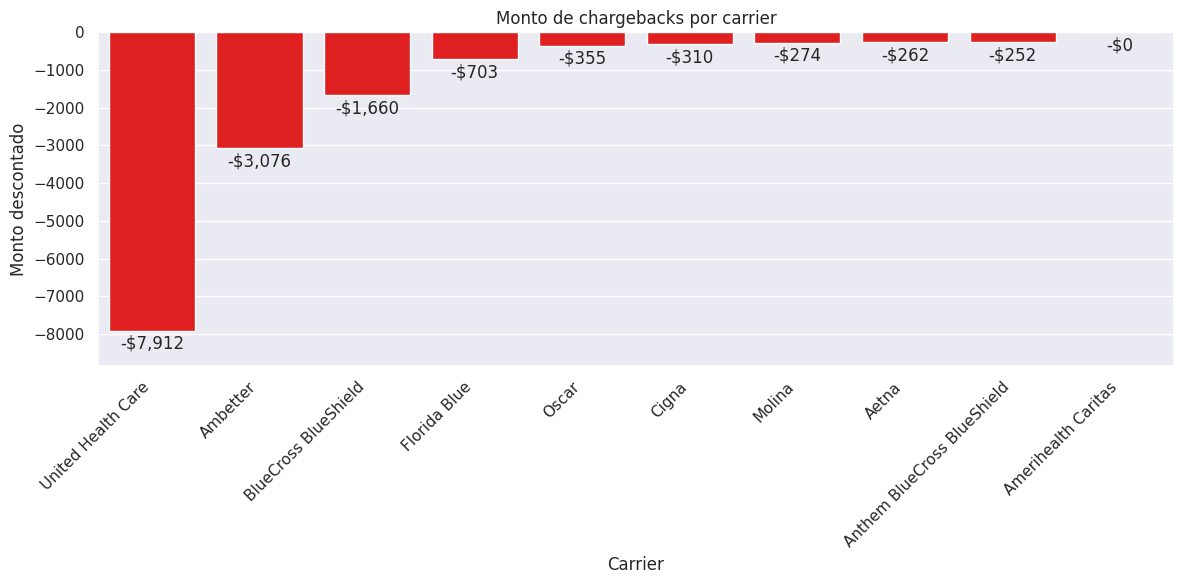

In [72]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme()

descuentos = df[df['Tipo_Pago'] == 'Chargeback']
monto = descuentos.groupby('carrier')['net_payment'].sum().sort_values()   # el más negativo primero

plt.figure(figsize=(12, 6))
ax = sns.barplot(x=monto.index, y=monto.values, color='red')

ax.bar_label(ax.containers[0], labels=[f'-${abs(v):,.0f}' for v in monto.values], padding=3)
ax.set_ylim(bottom=monto.min() * 1.12, top=0)   # espacio debajo para las etiquetas

plt.title('Monto de chargebacks por carrier')
plt.xlabel('Carrier')
plt.ylabel('Monto descontado')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

2. ¿En qué mes del 2026 recibió mayor cantidad de pagos por fecha de pago?

*Rpta: Se evidencia que los pagos más grandes los recibió en Enero y febrero, por 18.444 y 17.298 respectivamente, esto obedece al comportamiento de seguros de salud, en los cuales los primeros meses del año hay una alta demanda o pagos atrasados del 2025, y luego una caida*



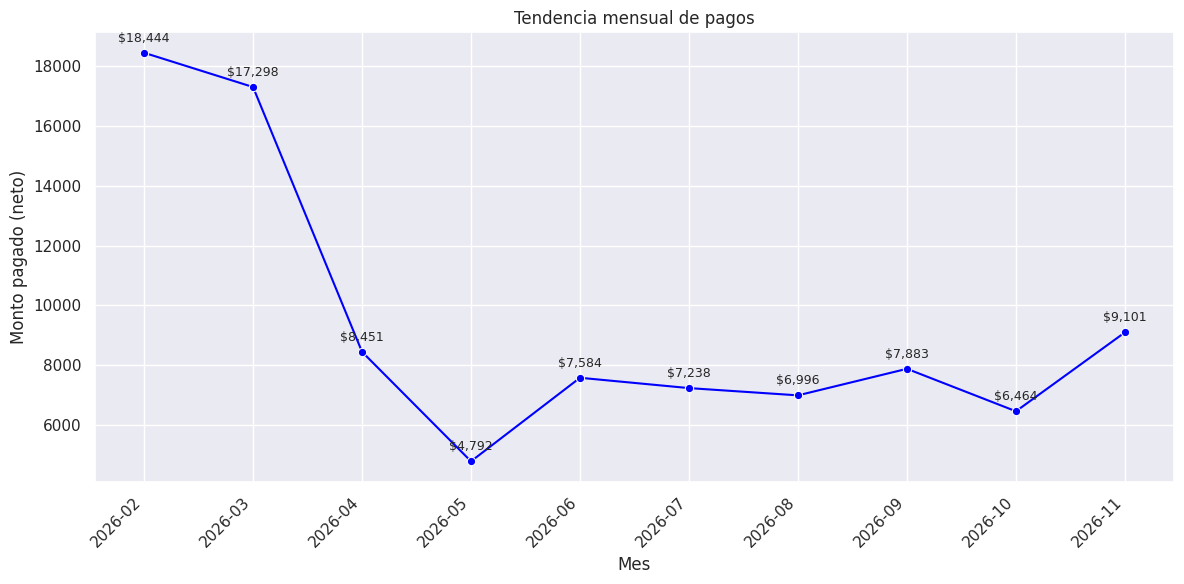

In [74]:
df['mes'] = pd.to_datetime(df['pay_on_date']).dt.to_period('M').astype(str)
tendencia = df.groupby('mes')['net_payment'].sum().reset_index()

plt.figure(figsize=(12, 6))
ax = sns.lineplot(data=tendencia, x='mes', y='net_payment', marker='o', color='blue')

for i, valor in enumerate(tendencia['net_payment']):
    texto = f'-${abs(valor):,.0f}' if valor < 0 else f'${valor:,.0f}'
    ax.annotate(texto, (i, valor),
                textcoords='offset points', xytext=(0, 8),
                ha='center', fontsize=9)

plt.title('Tendencia mensual de pagos')
plt.xlabel('Mes')
plt.ylabel('Monto pagado (neto)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

3. ¿Qué agente recibe mas pagos en promedio mes?

*Rpta: Los pagos se concentran en dos agentes, Andrew Fontalvo con un promedio asignado de 3.587 y a Juan caseres con 3.530. Los demás agentes reciben menos 1.000 y 6 agentes no reciben pago*

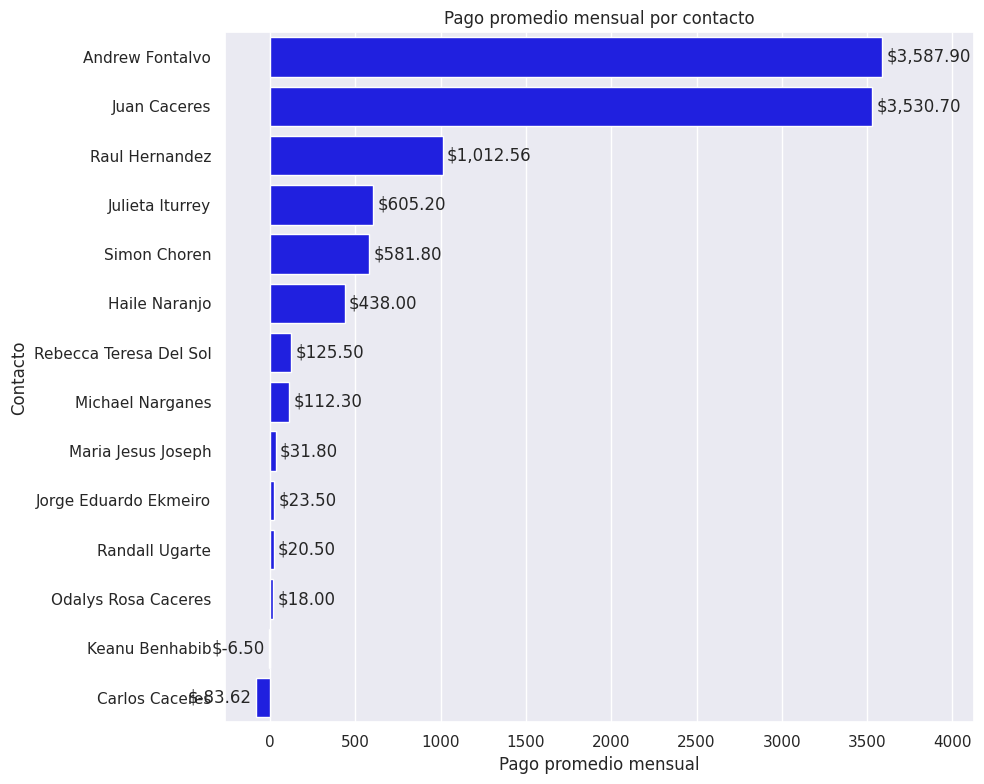

In [80]:
mensual = (df.groupby(['name_contact_payee', 'mes'])['net_payment']
             .sum()
             .reset_index())

promedio_agente = (mensual.groupby('name_contact_payee')['net_payment']
                     .mean()
                     .sort_values(ascending=False)
                     .reset_index())

plt.figure(figsize=(10, 8))
ax = sns.barplot(data=promedio_agente, y='name_contact_payee', x='net_payment', color='blue')

ax.bar_label(ax.containers[0], labels=[f'${v:,.2f}' for v in promedio_agente['net_payment']], padding=3)
ax.set_xlim(right=promedio_agente['net_payment'].max() * 1.15)

plt.title('Pago promedio mensual por contacto')
plt.xlabel('Pago promedio mensual')
plt.ylabel('Contacto')
plt.tight_layout()
plt.show()

4. ¿Cual es la tendencia de los pagos para las comisiones?

*Rpta: Febrero y marzo concentran el 37% del pago de las comisiones del año (unos 17.3K por mes), esto puede explicarse por la temporada alta para la venta de seguros de salud, o por pagos atrasados de los ultimos meses del 2025. Desde abril, el ingreso bajó a menos de la mitad y se estabilizó en un promedio de 7.4K mensuales. Podemos inferir que la estabilidad posterior indica que el impacto se concentró en ese corte y no siguió afectando el pago mes a mes, con un rango de pago de 6.1K a 8.8K y sin tendencia de crecimiento, situación negativa para la agencia*

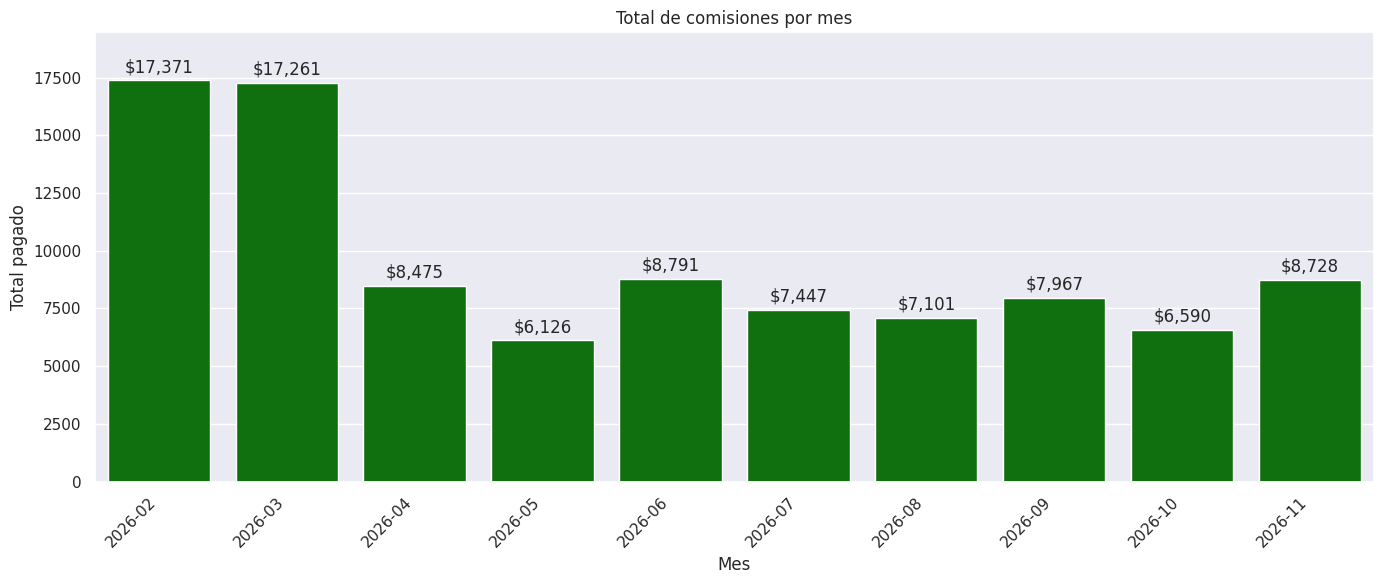

In [79]:
comisiones = (df[df['payment_type'] == 'Commission']
                .groupby('mes')['net_payment']
                .sum()
                .reset_index())

plt.figure(figsize=(14, 6))
ax = sns.barplot(data=comisiones, x='mes', y='net_payment', color='green')

ax.bar_label(ax.containers[0], labels=[f'${v:,.0f}' for v in comisiones['net_payment']], padding=3)
ax.set_ylim(top=comisiones['net_payment'].max() * 1.12)

plt.title('Total de comisiones por mes')
plt.xlabel('Mes')
plt.ylabel('Total pagado')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

5. ¿La agencia tiene algun pago pendiente?

*Rpta: Si, la agencia tiene un saldo pendiente para liquidar, 2.828,  se le ha pagado durante el 2026 un total de 91.348.*

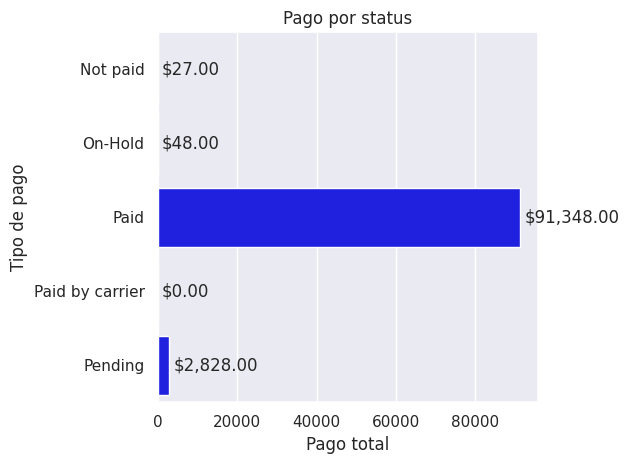

In [69]:
Pagos = df.groupby('payment_status')['net_payment'].sum().reset_index()

pg = sns.barplot(data=Pagos, y='payment_status', x='net_payment', color='blue')

pg.bar_label(pg.containers[0], labels=[f'${v:,.2f}' for v in Pagos['net_payment']], padding=3)

#pg.bar_label(pg.containers[0], fmt='$%.2f', padding=3)

plt.title('Pago por status')
plt.xlabel('Pago total')
plt.ylabel('Tipo de pago')
plt.tight_layout()
plt.show()


Conclusiones del análisis

    • Presenta al menos 3 conclusiones relevantes obtenidas a partir del análisis exploratorio.
    • Las conclusiones deben estar sustentadas en los datos y en los resultados obtenidos.
    • Menciona patrones, tendencias, relaciones o comportamientos importantes identificados en el conjunto de datos.
    • Evita limitarte a describir las gráficas; explica qué significan los resultados para el contexto del conjunto de datos.


*1. UnitedHealthcare registra el mayor volumen de descuentos (chargebacks). Aun así, en términos netos se mantiene dentro de los tres carriers que más pagos le han generado a la agencia en 2026. Su volumen positivo compensa ampliamente lo descontado.*

*2. La caída responde principalmente a la terminación de pólizas por non-compliance. Desde 2025, el mercado de salud enfrenta más reglas, validaciones y certificaciones, lo que hace más complejos tanto la venta de pólizas como el proceso de asignación de comisiones. Quedarse fuera de cumplimiento tiene un impacto directo en el volumen pagado tal como se evidencia en la caida de pagos de abril.*

*3. Para recibir pago, un agente debe tener un saldo positivo mínimo de $41. Hoy hay 6 agentes que no reciben pagos por no alcanzar ese mínimo. Dos de ellos, Keanu y Carlos, tienen saldo negativo, es decir, sus descuentos superan lo generado.*